# Práctica: **Clasificación multiclase** (MNIST) en PyTorch

Pasar de MLP con `D_out=2` (o 1+sigmoid) a MNIST: **`D_out=10` clases + `CrossEntropyLoss`** (que ya incluye softmax interno).

## 1. Carga del dataset
`torchvision` descarga MNIST (60k train + 10k test). Aplanamos cada imagen 28x28 → vector de 784 y normalizamos /255.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True)
print(len(trainset), len(testset))

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<01:08, 145kB/s]

  1%|          | 98.3k/9.91M [00:00<00:40, 240kB/s]

  2%|▏         | 164k/9.91M [00:00<00:36, 265kB/s] 

  3%|▎         | 262k/9.91M [00:00<00:31, 310kB/s]

...

 87%|████████▋ | 1.44M/1.65M [00:01<00:00, 1.83MB/s]

100%|██████████| 1.65M/1.65M [00:01<00:00, 1.35MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 2.34MB/s]

60000 10000


In [3]:
X = np.stack([np.asarray(img, dtype=np.float32).reshape(-1) for img, _ in trainset]) / 255.
y = np.array([lbl for _, lbl in trainset], dtype=np.int64)
X_test_mn = np.stack([np.asarray(img, dtype=np.float32).reshape(-1) for img, _ in testset]) / 255.
y_test_mn = np.array([lbl for _, lbl in testset], dtype=np.int64)
print('X:', X.shape, '| y:', y.shape, '| clases:', np.unique(y))

X: (60000, 784) | y: (60000,) | clases: [0 1 2 3 4 5 6 7 8 9]


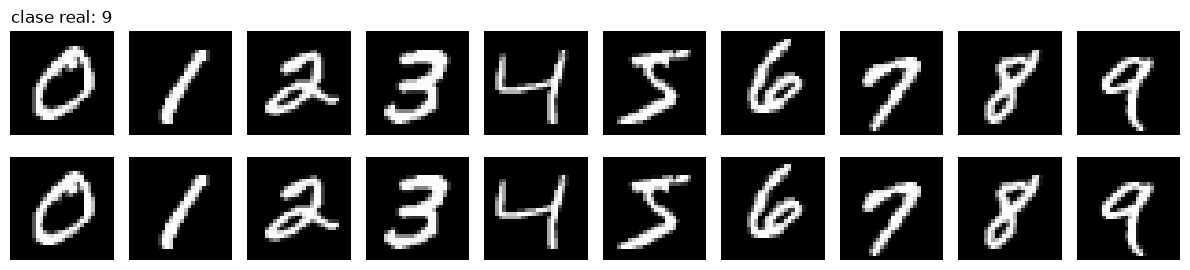

In [4]:
# visualizar algunos dígitos
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for i in range(10):
    ix = np.where(y == i)[0][0]
    for r in range(2):
        axes[r, i].imshow(X[ix].reshape(28, 28), cmap='gray')
        axes[r, i].axis('off')
axes[0, 0].set_title(f"clase real: {y[ix]}")
plt.tight_layout(); plt.show()

## 2. Split (ya balanceado como está; igual estratificamos)
En datasets grandes es normal experimentar con un **subconjunto** primero (la receta) antes de entrenar en todo.

In [5]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test_mn.shape[0]}")

X_subset, y_subset = X_train[:5000], y_train[:5000]   # para tune rápido
print("Subset para tune: ", X_subset.shape[0])

Train: 48000 | Val: 12000 | Test: 10000
Subset para tune:  5000


## 3. Dataset y DataLoader

In [6]:
class Dataset(torch.utils.data.Dataset):
    def __init__(self, X, Y):
        self.X = torch.from_numpy(X).float().to(device)
        self.Y = torch.from_numpy(Y).long().to(device)   # long() para etiquetas de clase
    def __len__(self):
        return len(self.X)
    def __getitem__(self, ix):
        return self.X[ix], self.Y[ix]

def hacer_dataloaders(dataset_tr, dataset_va, bs=64):
    return {
        'train': torch.utils.data.DataLoader(dataset_tr, batch_size=bs, shuffle=True),
        'val': torch.utils.data.DataLoader(dataset_va, batch_size=1000, shuffle=False),
    }

## 4. Modelo ⭐

`D_in=784`, `D_out=10` **sin softmax** al final (CrossEntropyLoss ya lo aplica por dentro).

In [7]:
D_in = 784
H = 128
D_out = 10

def build_model(D_in=D_in, H=H, D_out=D_out):
    return torch.nn.Sequential(
        torch.nn.Linear(D_in, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, D_out)   # 10 logits, sin softmax
    ).to(device)

## 5. Validación de la red (dims, fit 1 muestra, fit batch)

In [8]:
model = build_model()
out = model(torch.randn((64, D_in)).to(device))
print('Entrada:', (64, D_in), '-> Salida:', tuple(out.shape))
assert out.shape == (64, D_out)

Entrada: (64, 784) -> Salida: (64, 10)


In [9]:
criterion = torch.nn.CrossEntropyLoss()
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
ds1 = Dataset(X_subset[:8], y_subset[:8])
dl1 = torch.utils.data.DataLoader(ds1, batch_size=8)
for e in range(1, 101):
    for x_b, y_b in dl1:
        loss = criterion(model(x_b), y_b)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    if not e % 20:
        print(f"Epoch {e} loss {loss.item():.5f} pred {torch.argmax(model(x_b), axis=1).tolist()}")

Epoch 20 loss 0.00000 pred [1, 3, 6, 8, 6, 8, 5, 7]
Epoch 40 loss 0.00000 pred [1, 3, 6, 8, 6, 8, 5, 7]
Epoch 60 loss 0.00000 pred [1, 3, 6, 8, 6, 8, 5, 7]
Epoch 80 loss 0.00000 pred [1, 3, 6, 8, 6, 8, 5, 7]
Epoch 100 loss 0.00000 pred [1, 3, 6, 8, 6, 8, 5, 7]


## 6. Función de entrenamiento ⭐ (con **softmax→argmax** para calcular accuracy)

In [10]:
def softmax(x):
    return torch.exp(x) / torch.exp(x).sum(axis=-1, keepdims=True)

def fit(model, dataloader, optimizer, epochs=10, log_each=2, early_stopping=3, verbose=1):
    criterion = torch.nn.CrossEntropyLoss()
    l, acc, val_l, val_acc = [], [], [], []
    best_acc, steps = 0, 0
    for e in range(1, epochs + 1):
        model.train()
        _l, _acc = [], []
        for x_b, y_b in dataloader['train']:
            y_pred = model(x_b)
            loss = criterion(y_pred, y_b)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            _l.append(loss.item())
            _acc.append(accuracy_score(y_b.cpu().numpy(), torch.argmax(softmax(y_pred), axis=1).cpu().detach().numpy()))
        l.append(np.mean(_l)); acc.append(np.mean(_acc))
        model.eval()
        _vl, _vacc = [], []
        with torch.no_grad():
            for x_b, y_b in dataloader['val']:
                y_pred = model(x_b)
                _vl.append(criterion(y_pred, y_b).item())
                _vacc.append(accuracy_score(y_b.cpu().numpy(), torch.argmax(softmax(y_pred), axis=1).cpu().numpy()))
        val_l.append(np.mean(_vl)); val_acc.append(np.mean(_vacc))
        if val_acc[-1] > best_acc:
            best_acc = val_acc[-1]; steps = 0
            torch.save(model.state_dict(), 'ckpt_multi.pt')
        else:
            steps += 1
        if early_stopping and steps > early_stopping:
            print(f"Early stop en epoch {e}"); break
        if not e % log_each and verbose:
            print(f"Epoch {e}/{epochs} loss {l[-1]:.4f} acc {acc[-1]:.4f} val_acc {val_acc[-1]:.4f}")
    model.load_state_dict(torch.load('ckpt_multi.pt', weights_only=True))
    return {'loss': l, 'acc': acc, 'val_loss': val_l, 'val_acc': val_acc}

## 7. Tune rápido en subconjunto (la receta)

In [11]:
dl_sub = hacer_dataloaders(Dataset(X_subset, y_subset), Dataset(X_val[:3000], y_val[:3000]), bs=64)
for lr in [0.001, 0.0005]:
    model = build_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = fit(model, dl_sub, optimizer, epochs=5, verbose=0)
    print(f"lr={lr} -> val_acc final {hist['val_acc'][-1]:.4f}")

lr=0.001 -> val_acc final 0.9173


lr=0.0005 -> val_acc final 0.9063


## 8. Entrenar en todo el train (o en más datos) y evaluar

In [12]:
dataloader = hacer_dataloaders(Dataset(X_train, y_train), Dataset(X_val, y_val), bs=64)
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, dataloader, optimizer, epochs=20)

Epoch 2/20 loss 0.1451 acc 0.9570 val_acc 0.9625


Epoch 4/20 loss 0.0757 acc 0.9770 val_acc 0.9713


Epoch 6/20 loss 0.0455 acc 0.9858 val_acc 0.9662


Epoch 8/20 loss 0.0304 acc 0.9900 val_acc 0.9732


Epoch 10/20 loss 0.0223 acc 0.9929 val_acc 0.9703


Epoch 12/20 loss 0.0135 acc 0.9956 val_acc 0.9733


Epoch 14/20 loss 0.0130 acc 0.9957 val_acc 0.9706


Epoch 16/20 loss 0.0122 acc 0.9956 val_acc 0.9766


Epoch 18/20 loss 0.0106 acc 0.9965 val_acc 0.9766


Epoch 20/20 loss 0.0050 acc 0.9985 val_acc 0.9785


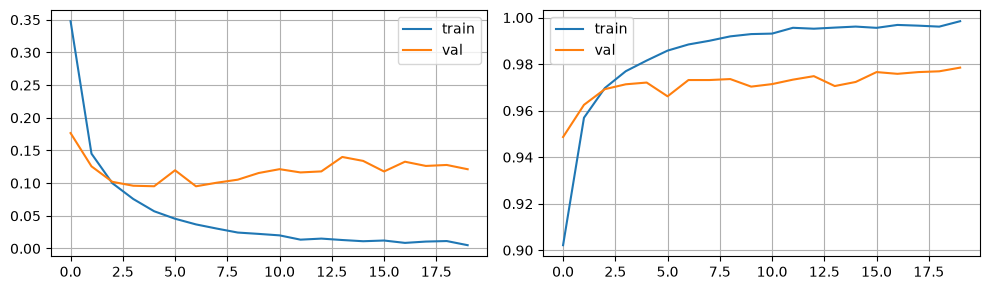

In [13]:
plt.figure(figsize=(10, 3))
plt.subplot(121); plt.plot(hist['loss'], label='train'); plt.plot(hist['val_loss'], label='val'); plt.legend(); plt.grid()
plt.subplot(122); plt.plot(hist['acc'], label='train'); plt.plot(hist['val_acc'], label='val'); plt.legend(); plt.grid()
plt.tight_layout(); plt.show()

In [14]:
model.eval()
with torch.no_grad():
    y_pred = torch.argmax(softmax(model(torch.from_numpy(X_test_mn).float().to(device))), axis=1).cpu().numpy()
print("Test accuracy:", round(accuracy_score(y_test_mn, y_pred), 4))

Test accuracy: 0.9802


## 9. Ver errores (muy útil para estudiar)

Errores: 198 de 10000


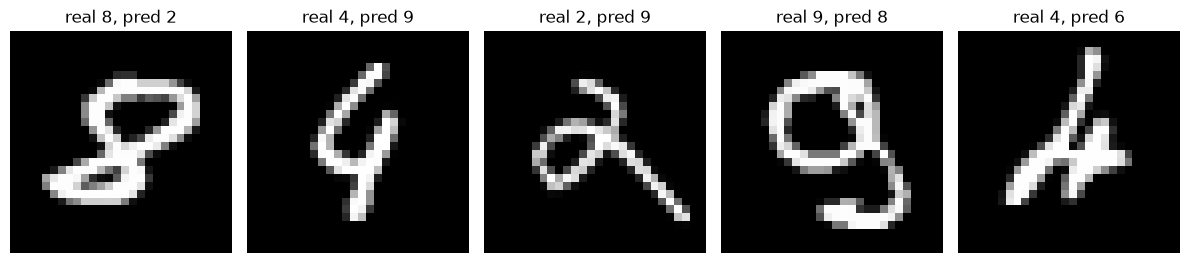

In [15]:
errors = np.where(y_pred != y_test_mn)[0]
print("Errores:", len(errors), "de", len(y_test_mn))
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ix in enumerate(errors[:5]):
    axes[i].imshow(X_test_mn[ix].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"real {y_test_mn[ix]}, pred {y_pred[ix]}")
    axes[i].axis('off')
plt.tight_layout(); plt.show()

## Recapitulación
1. Multiclase: `D_out=num_clases`, **CrossEntropyLoss** (sin softmax en el modelo).
2. Predicción final: `argmax(softmax(logits))`.
3. Etiquetas en el Dataset como `long()`, features como `float()`.
4. Tune rápido en un subconjunto antes de gastar tiempo en todo el dataset.
